# 03. 네 가지 학습 전략의 기본 학습 비교(E01~E04)

| ID | 전략 | 초기 가중치 | 학습 범위 |
|---|---|---|---|
| E01 | Scratch | 없음 | 전체 |
| E02 | Feature Extraction | ImageNet | `fc`만 |
| E03 | Partial FT | ImageNet | `layer4` + `fc` |
| E04 | Full FT | ImageNet | 전체 |

**공통 조건**(D-012·D-019·D-020): 공식 분할, Train 100%(8,144장), letterbox 224 + ImageNet 정규화, 증강 없음, Batch 32, AdamW(weight decay 1e-4), lr 1e-3(FT 백본만 1e-4), AMP, epoch 상한 50, Val Macro F1 기준 Early Stopping(patience 5) + 최고 시점 복원, seed 42, 결정적 모드.

**규칙**: 모든 수치는 Validation(3명, 1,440장)입니다. Test는 쓰지 않습니다. 실행은 한 번씩(seed 하나)이라, E00에서 본 것처럼 0.01~0.02 정도의 차이는 잡음일 수 있습니다.

**학습 전 가설**(01_eda 10.3절): Partial FT ≈ Full FT > Feature Extraction > Scratch

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import FIGURES, GROUPS, CLASS_TO_GROUP, class_names, set_korean_font

print("font:", set_korean_font())
pd.set_option("display.width", 180)
NAMES = class_names()
RUNS = {"E01": "scratch", "E02": "fe", "E03": "partial", "E04": "full"}
LABEL = {"scratch": "Scratch", "fe": "Feature Extraction", "partial": "Partial FT", "full": "Full FT"}
COLOR = {"scratch": "#E45756", "fe": "#F58518", "partial": "#54A24B", "full": "#4C78A8"}
H, S, C = {}, {}, {}
for rid, s in RUNS.items():
    d = ROOT / "experiments" / rid / s
    H[s] = pd.read_csv(d / "history.csv")
    S[s] = json.loads((d / "summary.json").read_text(encoding="utf-8"))
    C[s] = json.loads((d / "config.json").read_text(encoding="utf-8"))

font: Malgun Gothic


## 1. 한눈에 보는 결과

- **학습 파라미터 수**: 실제로 업데이트되는 가중치 개수(계산량·과적합 위험과 관련)
- **최고 epoch**: Val Macro F1이 가장 높았던 epoch(수렴 속도). 그 시점의 가중치로 되돌린 모델이 아래 지표입니다.
- **총 학습 시간**: Early Stopping으로 멈출 때까지 걸린 시간(학습 + 매 epoch Val 평가)

In [2]:
rows = []
for rid, s in RUNS.items():
    sm, h = S[s], H[s]
    b = h[h.epoch == sm["best_epoch"]].iloc[0]
    rows.append({
        "ID": rid, "전략": LABEL[s], "학습 파라미터": sm["params"]["trainable"],
        "최고 epoch": sm["best_epoch"], "돌린 epoch": sm["epochs_run"],
        "총 시간(분)": round(sm["total_time_s"] / 60, 1),
        "epoch당 학습(초)": round(h.train_time_s.iloc[1:].median(), 1),
        "Val Accuracy": round(sm["val"]["accuracy"], 4), "Val Macro F1": round(sm["val"]["macro_f1"], 4),
        "최고 시점 Train Acc": round(b.train_acc, 4),
        "GPU 메모리(MB)": round(sm["peak_gpu_mem_mb"]),
    })
summary = pd.DataFrame(rows)
summary["Train−Val Acc"] = (summary["최고 시점 Train Acc"] - summary["Val Accuracy"]).round(4)
summary

,ID,전략,학습 파라미터,최고 epoch,돌린 epoch,총 시간(분),epoch당 학습(초),Val Accuracy,Val Macro F1,최고 시점 Train Acc,GPU 메모리(MB),Train−Val Acc
0,E01,Scratch,11182668,9,14,3.0,9.5,0.7979,0.7928,0.9522,629,0.1543
1,E02,Feature Extraction,6156,13,18,2.7,5.9,0.7951,0.7678,0.8846,242,0.0895
2,E03,Partial FT,8399884,15,20,3.1,6.0,0.8500,0.8311,0.9932,339,0.1432
3,E04,Full FT,11182668,16,21,4.4,9.5,0.8660,0.8581,0.9983,629,0.1323


## 2. 학습 곡선: 수렴 속도와 과적합

- 왼쪽 두 그림: Train Loss(실선)와 Val Loss(점선). **Train은 계속 내려가는데 Val이 다시 올라가면 과적합**입니다.
- 오른쪽: epoch별 Val Macro F1. 별표가 최고 시점입니다.
- Train 지표는 학습 도중(가중치가 바뀌는 중)의 값이라 Val과 조건이 조금 다릅니다. 방향을 보는 용도입니다.

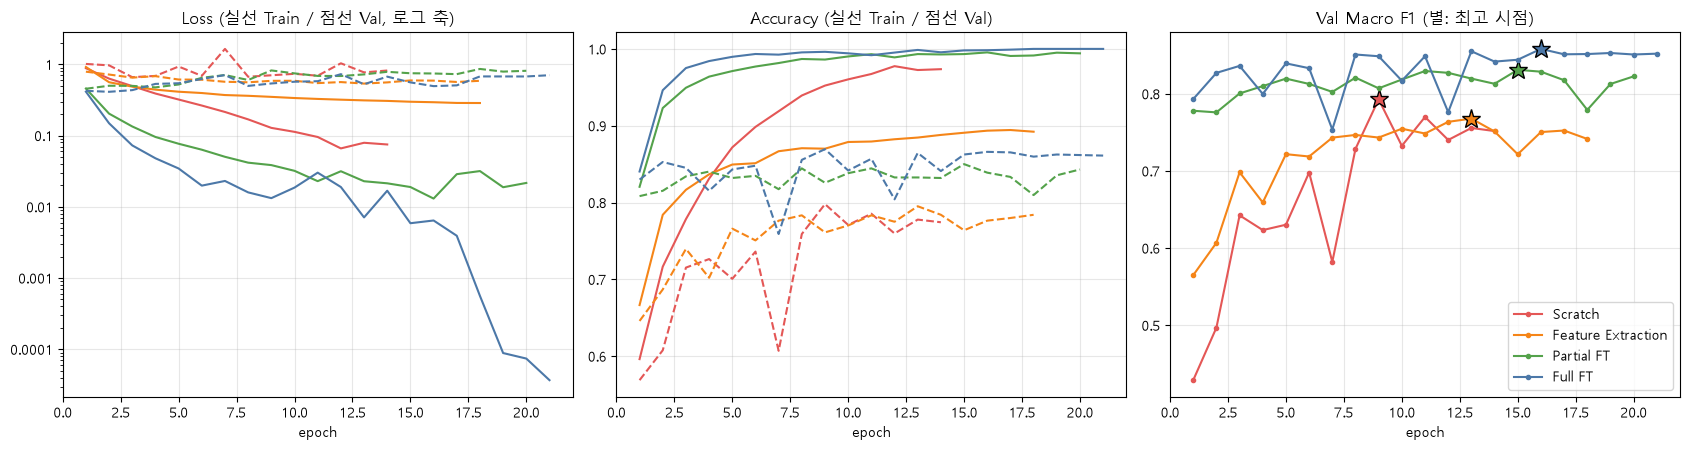

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for s, h in H.items():
    axes[0].plot(h.epoch, h.train_loss, color=COLOR[s], label=LABEL[s])
    axes[0].plot(h.epoch, h.val_loss, color=COLOR[s], ls="--")
    axes[1].plot(h.epoch, h.train_acc, color=COLOR[s], label=LABEL[s])
    axes[1].plot(h.epoch, h.val_acc, color=COLOR[s], ls="--")
    axes[2].plot(h.epoch, h.val_macro_f1, color=COLOR[s], label=LABEL[s], marker=".")
    be = S[s]["best_epoch"]
    axes[2].plot(be, h.val_macro_f1[h.epoch == be].iloc[0], marker="*", ms=14, color=COLOR[s], mec="k")
from matplotlib.ticker import FuncFormatter, NullFormatter
axes[0].set_title("Loss (실선 Train / 점선 Val, 로그 축)"); axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))  # 수식 글꼴 대신 일반 숫자로 표시
axes[0].yaxis.set_minor_formatter(NullFormatter())
axes[1].set_title("Accuracy (실선 Train / 점선 Val)")
axes[2].set_title("Val Macro F1 (별: 최고 시점)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=.3)
axes[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "e01_04_curves.png", dpi=110); plt.show()

## 3. 클래스별 성능

Macro F1은 12개 클래스의 F1 평균이라, 어느 운동에서 점수를 잃는지 봐야 합니다. Recall은 "그 운동 사진 중 맞힌 비율", Precision은 "그 운동이라고 예측한 것 중 맞은 비율"입니다. 행 순서는 촬영 묶음(맨몸 / 바벨·덤벨 / 기구)별입니다.

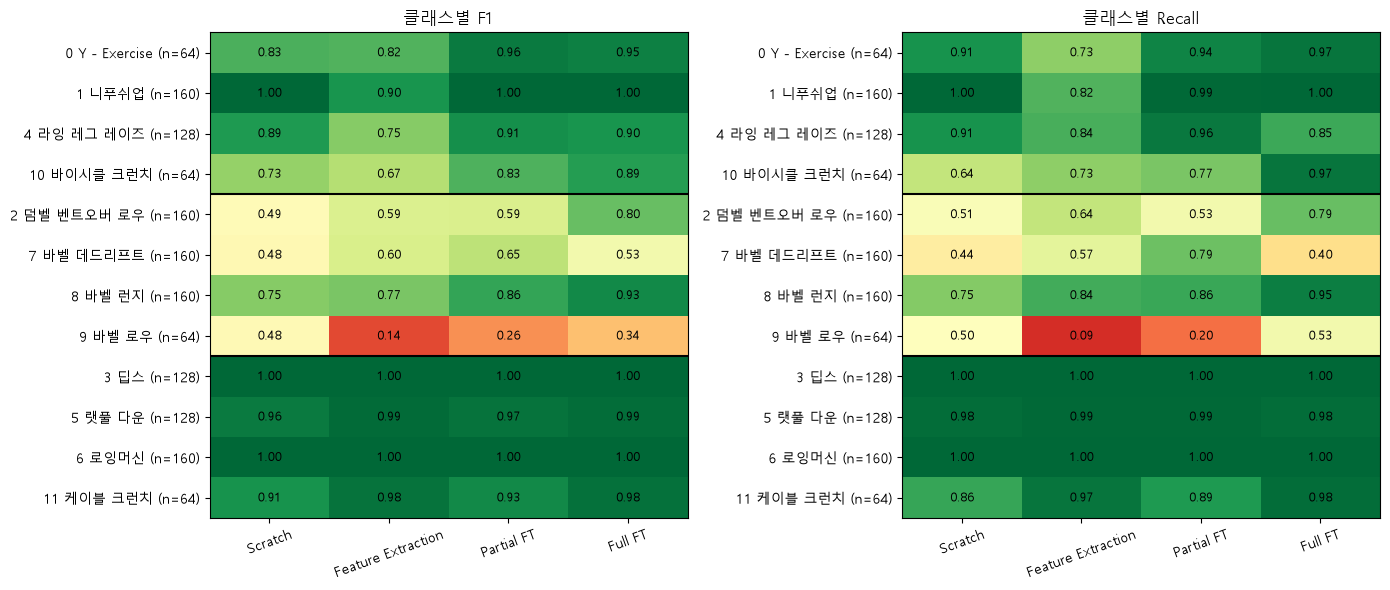

,묶음,Scratch,Feature Extraction,Partial FT,Full FT
0 Y - Exercise,맨몸(바닥),0.835,0.825,0.960,0.947
1 니푸쉬업,맨몸(바닥),1.000,0.904,0.997,1.000
4 라잉 레그 레이즈,맨몸(바닥),0.892,0.748,0.914,0.905
10 바이시클 크런치,맨몸(바닥),0.726,0.671,0.831,0.886
2 덤벨 벤트오버 로우,바벨·덤벨(선 자세),0.487,0.592,0.594,0.796
7 바벨 데드리프트,바벨·덤벨(선 자세),0.478,0.599,0.655,0.533
8 바벨 런지,바벨·덤벨(선 자세),0.748,0.769,0.864,0.930
9 바벨 로우,바벨·덤벨(선 자세),0.481,0.141,0.257,0.337
3 딥스,기구,1.000,1.000,1.000,1.000
5 랫풀 다운,기구,0.958,0.988,0.973,0.988


In [4]:
order = [c for g in GROUPS.values() for c in g]
def per_class(metric):
    df = pd.DataFrame({LABEL[s]: [S[s]["val"]["per_class"][metric][NAMES[c]] for c in order] for s in RUNS.values()},
                      index=[f"{c} {NAMES[c]}" for c in order])
    df.insert(0, "묶음", [CLASS_TO_GROUP[c] for c in order])
    return df
f1 = per_class("f1"); rec = per_class("recall")
support = [S["full"]["val"]["per_class"]["support"][NAMES[c]] for c in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, df, t in ((axes[0], f1, "클래스별 F1"), (axes[1], rec, "클래스별 Recall")):
    v = df.drop(columns="묶음").values
    im = ax.imshow(v, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(df.columns[1:], rotation=20)
    ax.set_yticks(range(12)); ax.set_yticklabels([f"{i} (n={n})" for i, n in zip(df.index, support)])
    for i in range(12):
        for j in range(4):
            ax.text(j, i, f"{v[i, j]:.2f}", ha="center", va="center", fontsize=9)
    for y in (3.5, 7.5): ax.axhline(y, color="k", lw=1.5)
    ax.set_title(t)
plt.tight_layout(); plt.savefig(FIGURES / "e01_04_per_class.png", dpi=110); plt.show()
f1.round(3)

## 4. Confusion Matrix: 어디서 헷갈리는가

행이 정답, 열이 예측이고 행마다 합이 1이 되게 나눴습니다(Recall 기준). 굵은 선은 촬영 묶음 경계입니다. **가설 H-a**: 오류는 묶음 *안*(굵은 선으로 나뉜 대각 블록 안)에 몰릴 것이다.

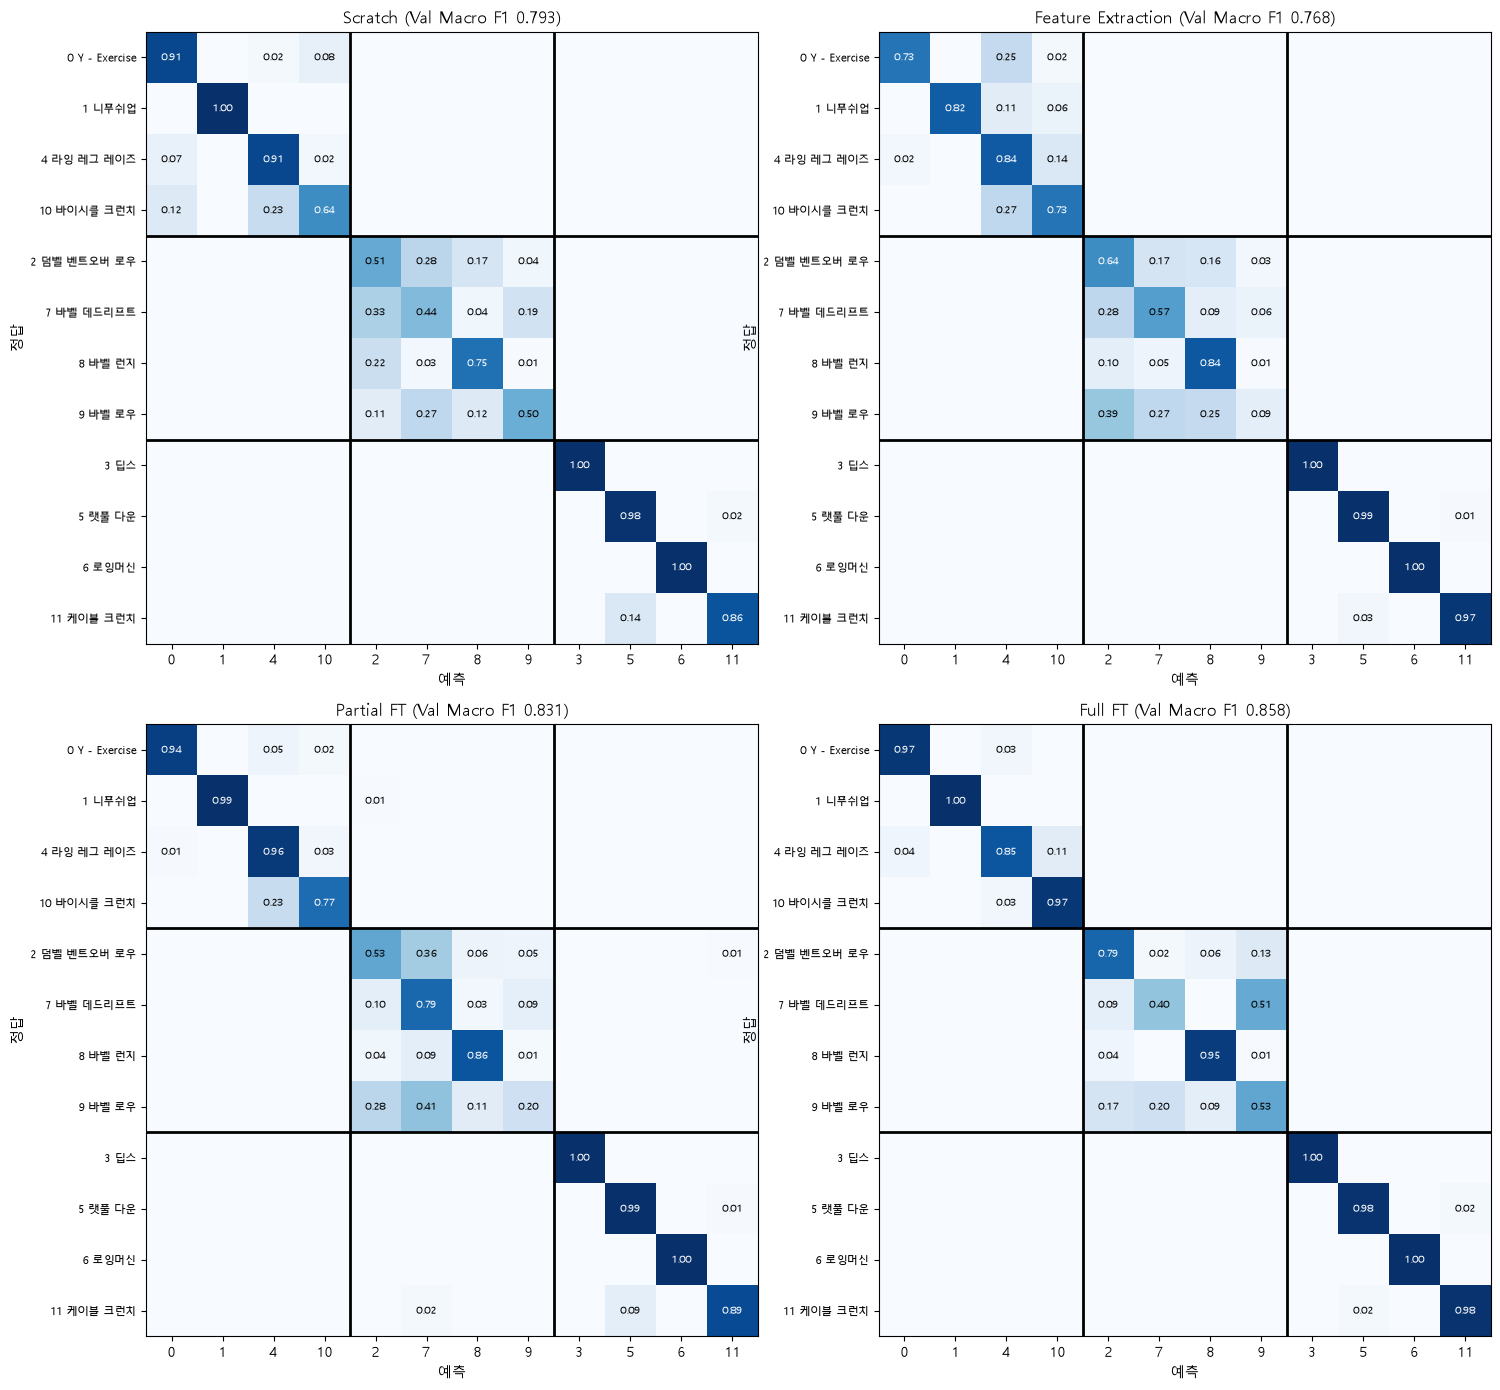

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 14))
for ax, s in zip(axes.ravel(), RUNS.values()):
    cm = np.array(S[s]["val"]["confusion_matrix"])[np.ix_(order, order)]
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(12):
        for j in range(12):
            if cm[i, j]: ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                                 color="white" if cmn[i, j] > .6 else "black")
    ax.set_xticks(range(12)); ax.set_xticklabels(order); ax.set_yticks(range(12))
    ax.set_yticklabels([f"{c} {NAMES[c]}" for c in order], fontsize=8)
    for p in (3.5, 7.5): ax.axhline(p, color="k", lw=2); ax.axvline(p, color="k", lw=2)
    ax.set_title(f"{LABEL[s]} (Val Macro F1 {S[s]['val']['macro_f1']:.3f})"); ax.set_xlabel("예측"); ax.set_ylabel("정답")
plt.tight_layout(); plt.savefig(FIGURES / "e01_04_confusion.png", dpi=100); plt.show()

In [6]:
rows = []
for s in RUNS.values():
    cm = np.array(S[s]["val"]["confusion_matrix"])
    wrong = cm.sum() - np.trace(cm)
    within = sum(cm[i, j] for i in range(12) for j in range(12) if i != j and CLASS_TO_GROUP[i] == CLASS_TO_GROUP[j])
    top = sorted(((cm[i, j], i, j) for i in range(12) for j in range(12) if i != j), reverse=True)[:3]
    rows.append({"전략": LABEL[s], "오답 수": int(wrong), "묶음 안 오답": int(within), "묶음 사이 오답": int(wrong - within),
                 "묶음 안 비율": round(within / wrong, 3) if wrong else None,
                 "가장 많은 혼동 3개(정답→예측: 장수)": ", ".join(f"{i}→{j}: {n}" for n, i, j in top)})
pd.DataFrame(rows)

,전략,오답 수,묶음 안 오답,묶음 사이 오답,묶음 안 비율,가장 많은 혼동 3개(정답→예측: 장수)
0,Scratch,291,291,0,1.000,"7→2: 53, 2→7: 45, 8→2: 35"
1,Feature Extraction,295,295,0,1.000,"7→2: 44, 2→7: 28, 9→2: 25"
2,Partial FT,216,213,3,0.986,"2→7: 57, 9→7: 26, 9→2: 18"
3,Full FT,193,193,0,1.000,"7→9: 82, 2→9: 21, 7→2: 14"


## 5. 해석

### 5.1 순서: Full FT > Partial FT > Scratch > Feature Extraction

| 전략 | Val Macro F1 | 학습 전 가설 |
|---|---|---|
| Full FT | **0.858** | 1위권(Partial과 비슷) |
| Partial FT | 0.831 | 1위권 |
| Scratch | 0.793 | 4위 |
| Feature Extraction | 0.768 | 3위 |

- **사전학습 + 미세조정(FT)이 가장 좋았습니다.** 가설과 맞습니다. Full이 Partial보다 0.027 높습니다. 처음부터 백본 전체를 우리 데이터에 맞추는 편이 나았습니다.
- **Scratch가 Feature Extraction보다 0.025 높았습니다. 가설과 다릅니다.** 근거는 두 가지입니다.
  - FE는 **덜 배웠습니다(과소적합).** 최고 시점 Train Accuracy가 0.885로 네 방식 중 가장 낮습니다. 고정된 ImageNet 특징 위에 선형 분류기(6,156개 가중치)만 얹어서는 Train도 다 맞히지 못합니다. 01_eda 10절에서 ImageNet 분류기가 우리 이미지를 "장면"으로 읽었습니다. 고정 특징에는 화면 속 작은 사람의 **자세** 정보가 충분히 담기지 않는 것으로 보입니다. 클래스별로 보면 FE는 맨몸 묶음(0·1·4·10)과 바벨 로우(F1 0.14)에서 가장 약합니다.
  - Scratch는 Train을 거의 외웠습니다(Train Acc 0.952, Val과 차이 0.154). Val 곡선도 크게 출렁입니다(7 epoch에 0.58까지 떨어짐). 그래도 자세에 맞춘 특징을 스스로 배워서 FE를 넘었습니다.
  - 결론: "데이터가 적으니 FE가 Scratch보다 낫다"는 생각은 이 데이터에서 맞지 않았습니다. **데이터가 ImageNet과 많이 다르면, 백본을 고정하는 것 자체가 제약**이 됩니다. 4분면에서 "다르고 적다" 칸의 권장(일부라도 미세조정)과 같은 방향입니다.
- **주의**: 실행은 seed 하나로 한 번씩입니다. E00에서 연산 방식만 바꿔도 F1이 0.01~0.04 움직였습니다. 따라서 Full > Partial(0.027), Scratch > FE(0.025)는 **반복 실행 전에는 "그럴 가능성이 높다" 수준**입니다. FT(0.83~0.86)와 FE·Scratch(0.77~0.79)의 차이는 그보다 커서 비교적 믿을 만합니다.

### 5.2 오류는 전부 묶음 안에서 납니다(가설 H-a 확인)

- 네 전략 모두 묶음 *사이* 오답이 거의 없습니다(Partial만 3장). 모델은 배경으로 촬영 묶음을 바로 압니다(01_eda의 평균 이미지 유사도 0.964 vs 0.206과 같은 이야기).
- **기구 묶음(3·5·6·11)은 거의 풀렸습니다**(F1 0.91~1.00). 기구 모양이 확실히 달라서입니다.
- **승부는 바벨·덤벨 묶음(2·7·8·9)입니다.** Full FT도 데드리프트 0.53, 바벨 로우 0.34의 F1입니다. 런지(8)는 자세가 달라 잘 맞힙니다.

### 5.3 데드리프트와 바벨 로우: 모델마다 헷갈리는 방향이 다름

| 전략 | 7 데드리프트 → 9 로우 | 9 로우 → 7 데드리프트 | 바벨 로우 Recall |
|---|---|---|---|
| Scratch | 19% | 27% | 0.50 |
| FE | 6% | 27% | 0.09 |
| Partial FT | 9% | 41% | 0.20 |
| Full FT | **51%** | 20% | 0.53 |

- 둘 다 바벨을 들고 상체를 숙였다 펴는 동작입니다. 01_eda에서 본 것처럼 **바벨 로우의 선 자세 프레임은 데드리프트를 다 든 순간과 거의 같습니다**(가설 H-e). 정지 이미지 한 장으로는 정보가 원래 부족한 쌍입니다.
- 전략마다 혼동 방향이 반대로 바뀝니다. 이는 모델이 둘 사이 경계를 안정적으로 배우지 못했다는 신호입니다. 바벨 로우는 Train에서도 가장 적은 클래스(312장)입니다.
- 어떤 프레임(카메라, 동작 단계)에서 틀리는지는 오류 분석(E06)에서 실제 이미지로 확인합니다.

### 5.4 Val 구성의 한계

- Val은 **운동마다 한 사람**입니다. 바벨·덤벨 묶음 4종은 모두 Z23 한 사람이고, 바벨 로우는 64장(8클립)뿐입니다.
- 한 클립의 8장은 거의 같은 장면이라, 실제로 독립적인 표본은 클립 수(8~20개)에 가깝습니다. 예를 들어 "Full FT가 데드리프트 82장을 로우로 예측"은 Z23의 데드리프트 클립 일부가 통째로 틀린 결과일 수 있습니다. 클래스별 수치는 **그 사람에 대한 결과**로 읽어야 합니다.

### 5.5 Loss와 F1이 다른 이야기를 합니다

- Full FT의 Val Loss는 2 epoch(0.41)가 가장 낮고 이후 올라갑니다. 그런데 Val Macro F1은 16 epoch에 가장 높습니다. Train Loss는 거의 0까지 내려갔습니다(18 epoch부터 Train Acc 1.000).
- 맞히는 개수(F1)는 유지되거나 늘어도, **틀린 예측에 점점 더 강하게 확신**하면 Loss가 커집니다(과신, overconfidence). Early Stopping 기준을 Val Loss로 했다면 2 epoch에서 멈췄을 것입니다. 기준 지표를 무엇으로 두는지가 결과를 바꿉니다. 이 프로젝트는 핵심 지표(Macro F1)로 정했습니다(D-012).

### 5.6 학습 비용

| 전략 | 학습 파라미터 | epoch당 학습 | 멈출 때까지 | 총 시간 |
|---|---|---|---|---|
| Scratch | 11,182,668 | 9.5초 | 14 epoch | 3.0분 |
| FE | 6,156 | 5.9초 | 18 epoch | 2.7분 |
| Partial FT | 8,399,884 | 6.0초 | 20 epoch | 3.1분 |
| Full FT | 11,182,668 | 9.5초 | 21 epoch | 4.4분 |

- FE는 epoch당 가장 빠르지만 천천히 오르다 멈춰서, 총 시간은 다른 방식과 큰 차이가 없습니다.
- Partial FT는 epoch당 시간이 FE와 거의 같습니다(역전파가 layer4까지만 감). Full과의 차이는 F1 0.027, 시간 1.3분입니다.
- 이 데이터 규모(8천 장)에서는 네 방식 모두 몇 분 안에 끝납니다. 그래서 비용보다 성능 차이가 선택을 좌우합니다.

### 5.7 다음 단계(튜닝 E05 후보, D-014: 한 번에 한 요인)

| 대상 | 관찰 | 후보 |
|---|---|---|
| Scratch | 과적합(차이 0.15), Val이 크게 출렁임 | 증강(좌우 뒤집기 + 약한 이동·확대). 또는 lr을 낮춤 |
| FE | 과소적합(Train Acc 0.885) | lr을 높임(1e-3 → 1e-2). 구조상 한계라 큰 개선은 기대하지 않음 |
| Full / Partial FT | Train을 다 외움, 2·7·9 혼동 | 증강, 또는 백본 lr 조정(1e-4 → 5e-5·3e-4) |